**0. Imports et installation**

In [1]:
!pip install ucimlrepo   # installe la bibliothèque qui télécharge le dataset

In [4]:
import numpy as np, pandas as pd, joblib           # calcul, tableaux, sauvegarde du scaler
import matplotlib.pyplot as plt                    # graphiques
import tensorflow as tf                            # moteur de calcul
from tensorflow import keras                       # interface pour construire le réseau
from tensorflow.keras import layers                # les couches (Dense, Dropout...)
from sklearn.model_selection import train_test_split   # séparer les données
from sklearn.preprocessing import StandardScaler, LabelEncoder  # standardiser / encoder
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report,
                             recall_score)         # mesures de qualité

SEED = 42                                  # graine pour des résultats reproductibles
keras.utils.set_random_seed(SEED)          # fixe le hasard de Keras
print("TensorFlow :", tf.__version__, "Keras :", keras.__version__)  # versions à noter
plt.rcParams.update({"figure.figsize": (7, 4), "font.size": 11})     # taille des figures

TensorFlow : 2.21.0 Keras : 3.13.2


**1.Lecture d’un petit MLP NumPy : ce qui se passe à l’intérieur**



x1 x2 | cible | probabilité initiale | finale | décision
[[0.         0.         1.         0.5        0.99907544 1.        ]
 [0.         1.         0.         0.41086294 0.00300052 0.        ]
 [1.         0.         0.         0.60371855 0.00306072 0.        ]
 [1.         1.         1.         0.52542099 0.99673409 1.        ]]


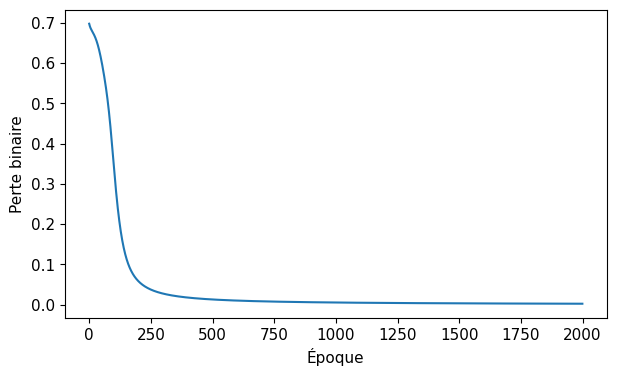

In [15]:
# Code fourni : exécuter et lire, sans le compléter.
class MiniMLP:
    def __init__(self, seed=5):
        rng = np.random.default_rng(seed)                      # hasard reproductible
        self.W1 = rng.normal(0, 1/np.sqrt(2), (2, 3))          # poids entrée -> cachée
        self.b1 = np.zeros((1, 3))                             # biais couche cachée
        self.W2 = rng.normal(0, 1/np.sqrt(3), (3, 1))          # poids cachée -> sortie
        self.b2 = np.zeros((1, 1))                             # biais de sortie

    def forward(self, X):
        # ÉTAPE 1 : propagation avant
        H = np.tanh(X @ self.W1 + self.b1)                     # couche cachée
        Z = H @ self.W2 + self.b2                              # sortie brute
        P = np.exp(-np.logaddexp(0, -Z))                       # sigmoïde stable -> probabilité
        return H, Z, P

    def fit(self, X, y, epochs=2000, rate=0.5):
        losses = []
        for _ in range(epochs):
            H, Z, P = self.forward(X)
            # ÉTAPE 2 : mesure de l'erreur par la perte
            losses.append(float(np.mean(np.logaddexp(0, Z) - y*Z)))
            # ÉTAPE 3 : rétropropagation
            D2 = (P-y)/len(y)
            dW2 = H.T @ D2
            db2 = D2.sum(axis=0, keepdims=True)
            D1 = (D2 @ self.W2.T) * (1-H**2)                   # erreur renvoyée vers la couche cachée
            dW1 = X.T @ D1
            db1 = D1.sum(axis=0, keepdims=True)
            # ÉTAPE 4 : mise à jour des paramètres
            self.W1 -= rate*dW1
            self.b1 -= rate*db1
            self.W2 -= rate*dW2
            self.b2 -= rate*db2
        return losses

X_logic = np.array([[0.,0.],[0.,1.],[1.,0.],[1.,1.]])          # entrées XNOR
y_logic = np.array([[1.],[0.],[0.],[1.]])                      # cibles XNOR
mini = MiniMLP()
initial_prob = mini.forward(X_logic)[2].copy()                 # probabilités avant apprentissage
logic_loss = mini.fit(X_logic, y_logic)                        # entraînement (2000 époques)
final_prob = mini.forward(X_logic)[2]                          # probabilités après
print("x1 x2 | cible | probabilité initiale | finale | décision")
print(np.column_stack([X_logic, y_logic, initial_prob, final_prob,
                      (final_prob >= 0.5).astype(int)]))
plt.plot(logic_loss)
plt.xlabel("Époque")
plt.ylabel("Perte binaire")
plt.show()
assert np.array_equal((final_prob >= 0.5).astype(int), y_logic.astype(int))

 **2.Charger et comprendre les données**



X : (13543, 16) y : (13543,)
Classes et effectifs : (array([0, 1, 2, 3, 4, 5, 6]), array([1322,  522, 1630, 3546, 1860, 2027, 2636]))


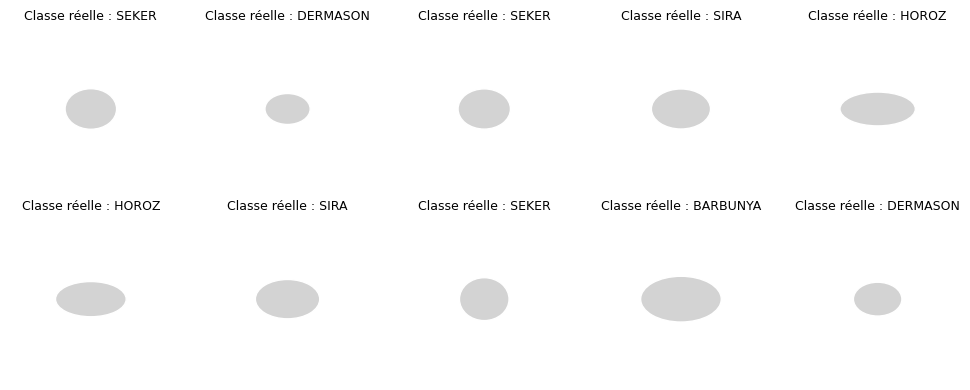

In [20]:
from matplotlib.patches import Ellipse

print("X :", X.shape, "y :", y.shape)
print("Classes et effectifs :", np.unique(y, return_counts=True))

# 10 haricots tirés au hasard (graine fixe = résultat reproductible)
rng = np.random.default_rng(SEED)
idx = rng.choice(len(full), size=10, replace=False)

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, i in zip(axes.ravel(), idx):
    row = full.iloc[i]
    # ellipse centrée : largeur = grand axe, hauteur = petit axe du haricot
    ax.add_patch(Ellipse((0, 0), row["MajorAxisLength"], row["MinorAxisLength"],
                         facecolor="lightgray", edgecolor="white"))
    ax.set_xlim(-400, 400)          # même échelle pour tous : on compare les tailles
    ax.set_ylim(-400, 400)
    ax.set_facecolor("black")       # fond noir comme les images digits
    ax.set_aspect("equal")
    ax.set_title(f"Classe réelle : {row['Class']}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [5]:
from ucimlrepo import fetch_ucirepo
dry_bean = fetch_ucirepo(id=602)                   # télécharge Dry Bean (id 602)
X_df = dry_bean.data.features                      # les 16 mesures (entrées)
y_raw = dry_bean.data.targets.values.ravel()       # le nom du haricot (cible)

print("X :", X_df.shape, "y :", y_raw.shape)       # dimensions
print("Types :\n", X_df.dtypes.value_counts())     # types des colonnes
print("Valeurs manquantes :", X_df.isna().sum().sum())     # cases vides
print("Effectifs :\n", pd.Series(y_raw).value_counts())    # nombre d'exemples par classe

full = X_df.copy()                                 # entrées + cible dans un seul tableau
full["Class"] = y_raw
print("Doublons exacts :", full.duplicated().sum())        # lignes identiques
full = full.drop_duplicates().reset_index(drop=True)       # on les retire AVANT la séparation

X = full.drop(columns="Class").values.astype("float32")    # entrées en tableau numpy
le = LabelEncoder()                                        # noms -> 0, 1, 2...
y = le.fit_transform(full["Class"]).astype("int64")        # cibles en entiers
print("Correspondance :", dict(enumerate(le.classes_)))    # indice -> nom
print("Après doublons :", X.shape)

N_FEATURES = X.shape[1]       # nombre d'entrées (16)
N_CLASSES = len(le.classes_)  # nombre de classes (7)

X : (13611, 16) y : (13611,)
Types :
 float64    14
int64       2
Name: count, dtype: int64
Valeurs manquantes : 0
Effectifs :
 DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64
Doublons exacts : 68
Correspondance : {0: 'BARBUNYA', 1: 'BOMBAY', 2: 'CALI', 3: 'DERMASON', 4: 'HOROZ', 5: 'SEKER', 6: 'SIRA'}
Après doublons : (13543, 16)


**3.Séparation et standardisation**

In [6]:
# 20 % pour le test (stratify = mêmes proportions de classes partout)
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
# 25 % du reste pour la validation (donc 60/20/20 au total)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=SEED)

scaler = StandardScaler()                   # centre et réduit
X_train_s = scaler.fit_transform(X_train)   # apprend moyenne/écart-type sur le TRAIN seulement
X_val_s = scaler.transform(X_val)           # mêmes valeurs appliquées à la validation
X_test_s = scaler.transform(X_test)         # et au test

print("Train / validation / test :", len(y_train), len(y_val), len(y_test))
assert np.allclose(scaler.mean_, X_train.mean(axis=0), atol=1e-4)  # vérifie le scaler

Train / validation / test : 8125 2709 2709


**4. Architecture 16-32-7**

In [7]:
model = keras.Sequential([
    keras.Input(shape=(N_FEATURES,)),                # une entrée = 16 nombres
    layers.Dense(32, activation="relu"),             # couche cachée : 32 neurones
    layers.Dense(N_CLASSES, activation="softmax"),   # sortie : 7 probabilités
])
model.summary()                                      # couches et paramètres
print("Paramètres :", model.count_params())
assert model.count_params() == 775                   # (16*32+32) + (32*7+7) = 544 + 231

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 775 (3.03 KB)

 Trainable params: 775 (3.03 KB)

 Non-trainable params: 0 (0.00 B)

Paramètres : 775


**5. compile**

In [8]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),  # comment corriger les poids
    loss=keras.losses.SparseCategoricalCrossentropy(),     # erreur à minimiser (cibles entières)
    metrics=["accuracy"],                                  # métrique affichée
)

**6. fit**

In [9]:
history = model.fit(X_train_s, y_train,                # données d'apprentissage
                    validation_data=(X_val_s, y_val),  # mesure seulement, sans apprendre
                    epochs=40,                         # 40 passages complets
                    batch_size=32,                     # une correction tous les 32 exemples
                    verbose=0)                         # pas d'affichage
print("Courbes :", list(history.history))
print("Époques exécutées :", len(history.history["loss"]))

Courbes : ['accuracy', 'loss', 'val_accuracy', 'val_loss']
Époques exécutées : 40


**7. Courbes**

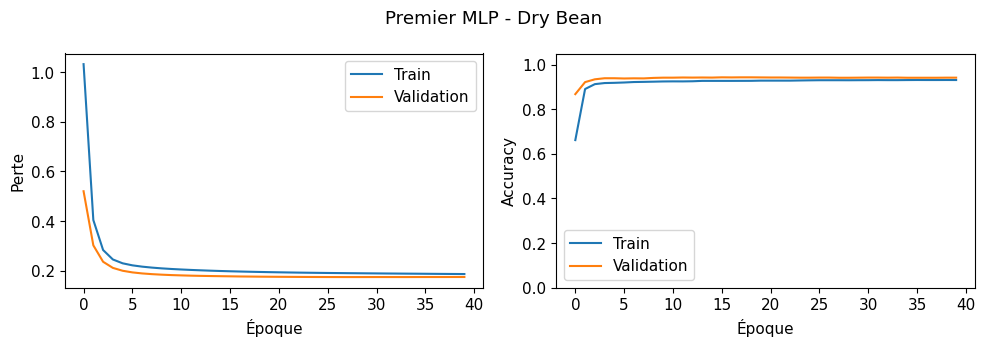

In [10]:
def plot_history(history, title):
    h = history.history                                  # dictionnaire des courbes
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))    # 2 graphiques côte à côte
    axes[0].plot(h["loss"], label="Train")               # perte train
    axes[0].plot(h["val_loss"], label="Validation")      # perte validation
    axes[0].set(xlabel="Époque", ylabel="Perte")
    axes[1].plot(h["accuracy"], label="Train")           # accuracy train
    axes[1].plot(h["val_accuracy"], label="Validation")  # accuracy validation
    axes[1].set(xlabel="Époque", ylabel="Accuracy", ylim=(0, 1.05))
    for ax in axes:
        ax.legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

plot_history(history, "Premier MLP - Dry Bean")

**8. evaluate, predict, matrice de confusion**

Évaluation : {'accuracy': 0.9416759014129639, 'loss': 0.17404727637767792}
Probabilités : (2709, 7)
              precision    recall  f1-score   support

    BARBUNYA      0.954     0.943     0.949       264
      BOMBAY      1.000     1.000     1.000       105
        CALI      0.939     0.951     0.945       326
    DERMASON      0.918     0.952     0.935       710
       HOROZ      0.965     0.960     0.962       372
       SEKER      0.968     0.965     0.967       405
        SIRA      0.920     0.879     0.899       527

    accuracy                          0.942      2709
   macro avg      0.952     0.950     0.951      2709
weighted avg      0.942     0.942     0.942      2709



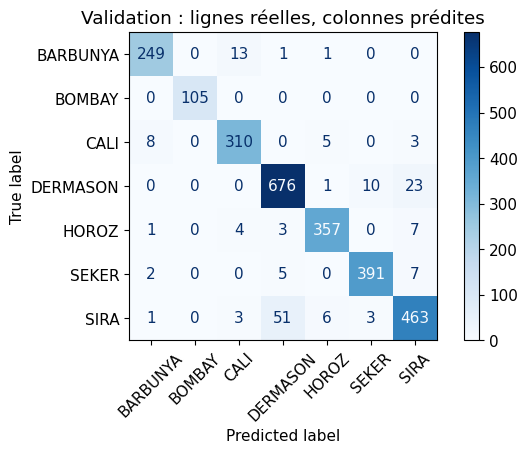

In [11]:
val_scores = model.evaluate(X_val_s, y_val, verbose=0, return_dict=True)  # perte + accuracy
prob_val = model.predict(X_val_s, verbose=0)     # 7 probabilités par haricot
pred_val = np.argmax(prob_val, axis=1)           # classe la plus probable

print("Évaluation :", val_scores)
print("Probabilités :", prob_val.shape)          # (~2709, 7)
assert np.allclose(prob_val.sum(axis=1), 1, atol=1e-5)   # chaque ligne somme à 1
# précision, rappel, F1 par classe
print(classification_report(y_val, pred_val, target_names=le.classes_,
                            digits=3, zero_division=0))
# matrice de confusion : lignes = réel, colonnes = prédit
cm_val = confusion_matrix(y_val, pred_val, labels=np.arange(N_CLASSES))
ConfusionMatrixDisplay(cm_val, display_labels=le.classes_).plot(
    cmap="Blues", xticks_rotation=45)
plt.title("Validation : lignes réelles, colonnes prédites")
plt.show()

**9. Comparer des réglages**

In [12]:
# Construit un modèle neuf selon les options choisies
def create_model(hidden=(32,), activation="relu", rate=0.001,
                 optimizer="adam", penalty=None, dropout=0.0, batchnorm=False,
                 input_dim=N_FEATURES, n_classes=N_CLASSES):
    keras.utils.set_random_seed(SEED)                     # mêmes poids de départ
    net = keras.Sequential([keras.Input(shape=(input_dim,))])
    for units in hidden:                                  # une couche cachée par valeur
        net.add(layers.Dense(units, kernel_regularizer=penalty))  # penalty = L1/L2 éventuel
        if batchnorm:
            net.add(layers.BatchNormalization())          # normalise à l'intérieur
        net.add(layers.Activation(activation))            # relu, tanh...
        if dropout > 0:
            net.add(layers.Dropout(dropout))              # éteint des neurones (entraînement)
    net.add(layers.Dense(n_classes, activation="softmax"))   # sortie
    opt = (keras.optimizers.Adam(learning_rate=rate) if optimizer == "adam"
           else keras.optimizers.SGD(learning_rate=rate))
    net.compile(optimizer=opt, loss="sparse_categorical_crossentropy",
                metrics=["accuracy"])
    return net

validation_loss = keras.losses.SparseCategoricalCrossentropy()
# Résume les scores d'un modèle sur la validation
def summarize(name, net, hist):
    proba = net.predict(X_val_s, verbose=0)               # probabilités
    pred = proba.argmax(axis=1)                           # classes prédites
    return {"modèle": name, "paramètres": net.count_params(),
            "époques": len(hist.history["loss"]),
            "CE_validation": float(validation_loss(y_val, proba).numpy()),  # sans pénalité
            "accuracy_validation": accuracy_score(y_val, pred),
            "F1_macro_validation": f1_score(y_val, pred, average="macro")}  # moyenne des F1

**Taux d’apprentissage**

{'modèle': 'Adam, taux=0.0001', 'paramètres': 775, 'époques': 30, 'CE_validation': 0.22070610523223877, 'accuracy_validation': 0.9346622369878184, 'F1_macro_validation': 0.9447009499125466}
{'modèle': 'Adam, taux=0.001', 'paramètres': 775, 'époques': 30, 'CE_validation': 0.17383450269699097, 'accuracy_validation': 0.9416758951642673, 'F1_macro_validation': 0.9504375365184458}
{'modèle': 'Adam, taux=0.05', 'paramètres': 775, 'époques': 30, 'CE_validation': 0.2860743999481201, 'accuracy_validation': 0.9176818014027316, 'F1_macro_validation': 0.9195724244711564}


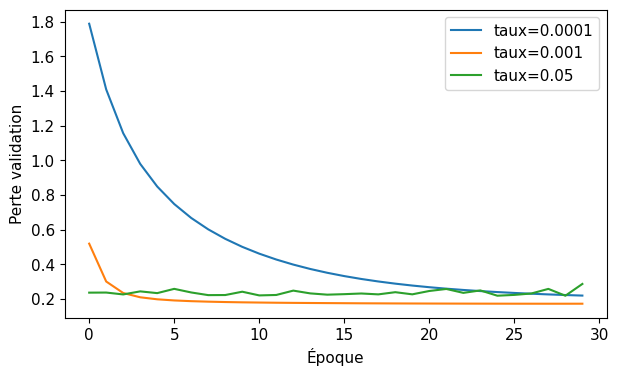

In [13]:
rate_runs = {}
for eta in [0.0001, 0.001, 0.05]:
    net = create_model(rate=eta)                          # modèle neuf par taux
    hist = net.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                   epochs=30, batch_size=32, verbose=0)
    rate_runs[eta] = (net, hist)
    print(summarize(f"Adam, taux={eta}", net, hist))      # scores
    plt.plot(hist.history["val_loss"], label=f"taux={eta}")  # courbe validation
plt.xlabel("Époque"); plt.ylabel("Perte validation"); plt.legend(); plt.show()

**Adam vs SGD**


In [14]:
optimizer_runs = {}
for opt in ["adam", "sgd"]:                               # seul l'optimisateur change
    net = create_model(rate=0.001, optimizer=opt)
    hist = net.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                   epochs=30, batch_size=32, verbose=0)
    optimizer_runs[opt] = (net, hist)
    print(summarize(opt, net, hist))

{'modèle': 'adam', 'paramètres': 775, 'époques': 30, 'CE_validation': 0.17383450269699097, 'accuracy_validation': 0.9416758951642673, 'F1_macro_validation': 0.9504375365184458}
{'modèle': 'sgd', 'paramètres': 775, 'époques': 30, 'CE_validation': 0.4566623270511627, 'accuracy_validation': 0.8955334071613141, 'F1_macro_validation': 0.9104125967067326}


**Tailles de lots (j’ai remplacé 1 par 8 : avec ~8 000 exemples, un lot de 1 ferait 8 000 mises à jour par époque, donc très lent)**

In [21]:
batch_runs = {}
for size in [8, 32, len(y_train)]:                        # petit lot, mini-lot, lot complet
    net = create_model(rate=0.01, optimizer="sgd")
    hist = net.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                   epochs=10, batch_size=size, verbose=0)
    batch_runs[size] = (net, hist)
    print(summarize(f"SGD, lot={size}", net, hist))
    print("Mises à jour par époque :", int(np.ceil(len(y_train) / size)))

{'modèle': 'SGD, lot=8', 'paramètres': 775, 'époques': 10, 'CE_validation': 0.18754245340824127, 'accuracy_validation': 0.9383536360280547, 'F1_macro_validation': 0.9470224490550609}
Mises à jour par époque : 1016
{'modèle': 'SGD, lot=32', 'paramètres': 775, 'époques': 10, 'CE_validation': 0.2420877367258072, 'accuracy_validation': 0.932078257659653, 'F1_macro_validation': 0.9418374696239391}
Mises à jour par époque : 254
{'modèle': 'SGD, lot=8125', 'paramètres': 775, 'époques': 10, 'CE_validation': 2.1479339599609375, 'accuracy_validation': 0.022886674049464747, 'F1_macro_validation': 0.019080002286750504}
Mises à jour par époque : 1


**Couches cachées et activations**

In [23]:
architecture_runs = {}
for name, hidden, activation in [
        ("étroit", (2,), "relu"), ("référence", (32,), "relu"),   # largeur
        ("deux couches", (64, 32), "relu"), ("tanh", (32,), "tanh")]:  # profondeur, activation
    net = create_model(hidden=hidden, activation=activation)
    hist = net.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                   epochs=30, batch_size=32, verbose=0)
    architecture_runs[name] = (net, hist)
    print(summarize(name, net, hist))

{'modèle': 'étroit', 'paramètres': 55, 'époques': 30, 'CE_validation': 0.36673083901405334, 'accuracy_validation': 0.9099298634182356, 'F1_macro_validation': 0.9174757246101428}
{'modèle': 'référence', 'paramètres': 775, 'époques': 30, 'CE_validation': 0.17383450269699097, 'accuracy_validation': 0.9416758951642673, 'F1_macro_validation': 0.9504375365184458}
{'modèle': 'deux couches', 'paramètres': 3399, 'époques': 30, 'CE_validation': 0.17599545419216156, 'accuracy_validation': 0.9401993355481728, 'F1_macro_validation': 0.9507952835415084}
{'modèle': 'tanh', 'paramètres': 775, 'époques': 30, 'CE_validation': 0.1758110076189041, 'accuracy_validation': 0.9420450350682908, 'F1_macro_validation': 0.9507041035622522}


**10. Régularisation**

{'modèle': 'référence', 'paramètres': 3399, 'époques': 35, 'CE_validation': 0.17630501091480255, 'accuracy_validation': 0.94093761535622, 'F1_macro_validation': 0.951395503463664}
Perte evaluate (pénalité incluse) : 0.1763048619031906
{'modèle': 'L1', 'paramètres': 3399, 'époques': 35, 'CE_validation': 0.17332200706005096, 'accuracy_validation': 0.9416758951642673, 'F1_macro_validation': 0.9518450003564676}
Perte evaluate (pénalité incluse) : 0.20516254007816315
{'modèle': 'L2', 'paramètres': 3399, 'époques': 35, 'CE_validation': 0.17429755628108978, 'accuracy_validation': 0.9405684754521964, 'F1_macro_validation': 0.9507818930582693}
Perte evaluate (pénalité incluse) : 0.20452362298965454
{'modèle': 'Dropout', 'paramètres': 3399, 'époques': 35, 'CE_validation': 0.17951329052448273, 'accuracy_validation': 0.9398301956441492, 'F1_macro_validation': 0.9505932701866534}
Perte evaluate (pénalité incluse) : 0.1795131266117096
{'modèle': 'BatchNorm', 'paramètres': 3783, 'époques': 35, 'CE_va

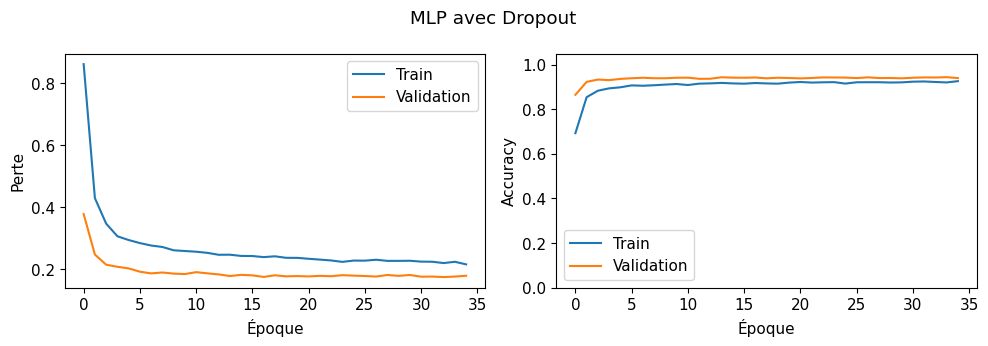

In [24]:
regularization_runs = {}
configs = [
    ("référence", {}),                                     # sans rien
    ("L1", {"penalty": keras.regularizers.l1(0.0001)}),    # pénalise |poids|
    ("L2", {"penalty": keras.regularizers.l2(0.001)}),     # pénalise poids²
    ("Dropout", {"dropout": 0.25}),                        # éteint 25 % des neurones
    ("BatchNorm", {"batchnorm": True}),                    # normalise dans le réseau
]
for name, options in configs:
    net = create_model(hidden=(64, 32), **options)         # 2 couches + une option
    hist = net.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                   epochs=35, batch_size=32, verbose=0)
    regularization_runs[name] = (net, hist)
    print(summarize(name, net, hist))
    # cette perte inclut la pénalité L1/L2, donc peut être plus grande
    print("Perte evaluate (pénalité incluse) :",
          net.evaluate(X_val_s, y_val, verbose=0, return_dict=True)["loss"])
plot_history(regularization_runs["Dropout"][1], "MLP avec Dropout")

**Diagnostic Dropout**

In [25]:
probe = keras.Sequential([
    keras.Input(shape=(N_FEATURES,)), layers.Dense(16, activation="relu"),
    layers.Dropout(0.5), layers.Dense(N_CLASSES, activation="softmax")])
eval1 = probe(X_val_s[:8], training=False).numpy()    # mode évaluation (Dropout éteint)
eval2 = probe(X_val_s[:8], training=False).numpy()
train1 = probe(X_val_s[:8], training=True).numpy()    # mode entraînement (Dropout actif)
train2 = probe(X_val_s[:8], training=True).numpy()
print("Évaluation identique :", np.allclose(eval1, eval2))      # attendu : True
print("Entraînement identique :", np.allclose(train1, train2))  # attendu : False

Évaluation identique : True
Entraînement identique : False


**11. EarlyStopping**

Époques exécutées : 36
Meilleure époque : 28
{'accuracy': 0.9413067698478699, 'loss': 0.1737634241580963}


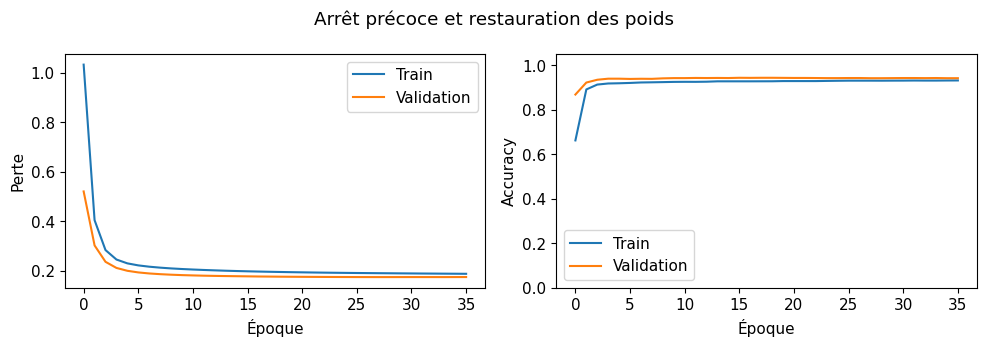

In [26]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",           # surveille la perte de validation
    patience=8,                   # 8 époques sans amélioration autorisées
    min_delta=0,                  # toute amélioration compte
    restore_best_weights=True)    # garde les meilleurs poids
early_model = create_model()
early_history = early_model.fit(
    X_train_s, y_train, validation_data=(X_val_s, y_val),
    epochs=100, batch_size=32,    # 100 max, arrêt possible avant
    callbacks=[early_stop], verbose=0)

print("Époques exécutées :", len(early_history.history["loss"]))
print("Meilleure époque :", 1 + np.argmin(early_history.history["val_loss"]))
print(early_model.evaluate(X_val_s, y_val, verbose=0, return_dict=True))
plot_history(early_history, "Arrêt précoce et restauration des poids")

**12. Sauvegarde et rechargement**

In [27]:
early_model.save("modele_drybean.keras")           # architecture + poids
joblib.dump(scaler, "scaler_drybean.joblib")       # scaler à part (absent du .keras)
joblib.dump(le, "labelencoder_drybean.joblib")     # correspondance indice <-> variété
loaded_model = keras.models.load_model("modele_drybean.keras")   # rechargement

p_before = early_model.predict(X_val_s[:5], verbose=0)
p_after = loaded_model.predict(X_val_s[:5], verbose=0)
print("Prédictions conservées :", np.allclose(p_before, p_after, atol=1e-6))
assert np.allclose(p_before, p_after, atol=1e-6)

Prédictions conservées : True
